# Industrial Energy Forecasting — Model Development & Selection
**Member 4 contribution | Daniel Puah**

This notebook develops, tunes, and compares three regression model families on the agreed 14-feature set from `02_feature_engineering.ipynb`:
- **Linear Regression** (parametric baseline, plus an L2-regularised Ridge diagnostic check for collinearity)
- **Random Forest** (bagged tree ensemble candidate)
- **Gradient Boosting** (boosted tree ensemble candidate)

### Methodology & Governance
1. **Strict Test Holdout:** The test period (`split == 'test'`, 5,184 rows) is dropped immediately upon loading and is never accessed in this notebook.
2. **Validation-Based Tuning & Selection:** Hyperparameters for Random Forest and Gradient Boosting are tuned exclusively on the chronological validation split (`2018-09-16 00:15` to `2018-11-08 00:00`, 5,088 rows) using **validation RMSE** as the primary selection criterion (since large errors during peak industrial load intervals carry the highest operational cost).
3. **Multi-Metric & Temporal Stability Checks:** Models are compared against the three naive benchmarks (`Persistence`, `Daily seasonal`, `Weekly seasonal`) across RMSE, MAE, $R^2$, 95th-percentile tail error (`P95_AE`), Maximum-Load RMSE, generalisation gap (`val_RMSE - train_RMSE`), and 5-fold expanding-window chronological cross-validation (`TimeSeriesSplit`).
4. **Handover to Evaluation (Feng):** Once hyperparameters and model selection are frozen, all three models are refitted on `train + validation` (`29,184` rows) and exported to `outputs/models/` alongside `frozen_config.json`.

## 1 Load the feature table and agreed feature list

In [1]:
from pathlib import Path
import json
import platform
import time
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'all_datasets' / 'steel_features.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run 02_feature_engineering.ipynb first.')
FEAT_DIR = ROOT / 'outputs' / 'features'
OUT = ROOT / 'outputs' / 'models'
FIG = ROOT / 'outputs' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

feature_list = json.loads((FEAT_DIR / 'feature_list.json').read_text())
FEATURES = feature_list['selected_features']
CATEGORICAL = feature_list['categorical_features']
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
TARGET = feature_list['target']
BENCHMARKS = feature_list['benchmarks']

data = pd.read_csv(ROOT / 'all_datasets' / 'steel_features.csv', parse_dates=['date', 'origin'])
dev = data[data.split != 'test'].reset_index(drop=True)
n_test = int((data.split == 'test').sum())
del data                                    # the test period is not used again in this notebook
train = dev[dev.split == 'train']
val = dev[dev.split == 'validation']
assert train.date.max() < val.date.min(), 'Training must precede validation.'
assert dev[FEATURES].isna().sum().sum() == 0
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)
print(f'Train {len(train):,} | Validation {len(val):,} | Test held out {n_test:,} (not loaded further)')
print('Features (%d):' % len(FEATURES), FEATURES)

Python: 3.14.6 | scikit-learn: 1.9.0
Train 24,096 | Validation 5,088 | Test held out 5,184 (not loaded further)
Features (14): ['tod_sin', 'tod_cos', 'hour', 'day_of_week', 'is_weekend', 'usage_lag_1', 'usage_lag_2', 'usage_lag_3', 'usage_lag_4', 'usage_diff_1', 'lag_reactive_kvarh_lag_1', 'lead_reactive_kvarh_lag_1', 'lag_power_factor_lag_1', 'lead_power_factor_lag_1']


## 2 Plotting style and metric helper
MAE and RMSE are in kWh per 15-minute interval. $R^2$ is relative to predicting the mean of the evaluated period.

In [2]:
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10,
    'legend.frameon': False, 'lines.linewidth': 1.5, 'figure.dpi': 110,
})

def metrics(y, pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
            'R2': r2_score(y, pred)}

X_tr, y_tr = train[FEATURES], train[TARGET]
X_va, y_va = val[FEATURES], val[TARGET]

## 3 Linear Regression baseline and regularisation check
Linear Regression cannot learn a curved daily profile from a single integer hour column, so `hour` and `day_of_week` are one-hot encoded (`drop='first'`) and the 12 numeric predictors are standardised (`StandardScaler`). Both transformations are fitted strictly on the training split inside a `Pipeline`.

Because `usage_diff_1 = usage_lag_1 - usage_lag_2` is an exact linear combination of lags 1 and 2, and cyclical `tod_sin`/`tod_cos` overlap with one-hot `hour`, we also check an L2-regularised `RidgeCV` pipeline across $\alpha \in \{0.01, 0.1, 1.0, 10.0, 100.0\}$ to verify whether multicollinearity inflates validation error.

In [3]:
def make_linear():
    prep = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CATEGORICAL),
        ('num', StandardScaler(), NUMERIC)])
    return Pipeline([('prep', prep), ('model', LinearRegression())])

linear = make_linear().fit(X_tr, y_tr)
results = {'Linear Regression': {'params': {}, 'model': linear}}
lin_val = metrics(y_va, linear.predict(X_va))
print('OLS Linear Regression Validation:', {k: round(v, 3) for k, v in lin_val.items()})

# Diagnostic check: does L2 regularisation (Ridge) improve the linear baseline?
ridge_pipe = Pipeline([
    ('prep', ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CATEGORICAL),
        ('num', StandardScaler(), NUMERIC)])),
    ('model', RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0]))
]).fit(X_tr, y_tr)
ridge_val = metrics(y_va, ridge_pipe.predict(X_va))
print(f"RidgeCV (best alpha={ridge_pipe.named_steps['model'].alpha_}) Validation:",
      {k: round(v, 3) for k, v in ridge_val.items()})

# Export top standardised numeric coefficients from Ridge for interpretability
num_coefs = pd.DataFrame({
    'feature': NUMERIC,
    'std_coef_ols': linear.named_steps['model'].coef_[-len(NUMERIC):],
    'std_coef_ridge': ridge_pipe.named_steps['model'].coef_[-len(NUMERIC):]
}).sort_values('std_coef_ridge', key= lambda s: s.abs(), ascending=False)
num_coefs.to_csv(OUT / 'linear_coefficients.csv', index=False)
print('\nTop numeric linear coefficients (standardised):')
print(num_coefs.head(6).round(3).to_string(index=False))

OLS Linear Regression Validation: {'MAE': 6.571, 'RMSE': 11.191, 'R2': 0.868}


RidgeCV (best alpha=1.0) Validation: {'MAE': 6.57, 'RMSE': 11.191, 'R2': 0.868}

Top numeric linear coefficients (standardised):
                feature  std_coef_ols  std_coef_ridge
            usage_lag_1        12.717          12.710
            usage_lag_2        11.006          10.998
            usage_lag_3         4.393           4.392
           usage_diff_1         4.017           4.019
lead_power_factor_lag_1         2.698           2.696
 lag_power_factor_lag_1         2.585           2.587


**Interpretation of Linear Baseline:** L2 regularisation (`RidgeCV`) shrinks the collinear lag coefficients (`usage_lag_1`, `usage_lag_2`, `usage_diff_1`), yet validation RMSE (`11.191 kWh`) is virtually identical to OLS (`11.191 kWh`). This confirms that the linear model's limitation is **structural additivity** (inability to model non-linear interactions between time-of-day shift changes and recent usage), rather than coefficient variance. We retain the standard `Linear Regression` pipeline as the parametric baseline.

## 4 Tune the Random Forest on the validation period
The grid searches tree depth (`max_depth`), minimum leaf size (`min_samples_leaf`), and the fraction of features considered at each split (`max_features`). Every candidate is trained on the training period and scored on validation RMSE. RMSE is the selection metric because large misses on peak intervals matter most for industrial energy planning.

In [4]:
RF_GRID = ParameterGrid({'max_depth': [None, 16], 'min_samples_leaf': [1, 5, 20], 'max_features': [1.0, 0.5]})
rf_log = []
for params in RF_GRID:
    t0 = time.time()
    rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **params).fit(X_tr, y_tr)
    rf_log.append({**params, **metrics(y_va, rf.predict(X_va)), 'fit_seconds': round(time.time() - t0, 1)})
rf_log = pd.DataFrame(rf_log).sort_values('RMSE')
rf_log.to_csv(OUT / 'tuning_random_forest.csv', index=False)
print(rf_log.round(3).to_string(index=False))

best = rf_log.iloc[0]
rf_params = {'n_estimators': 200, 'max_depth': None if pd.isna(best.max_depth) else int(best.max_depth),
             'min_samples_leaf': int(best.min_samples_leaf), 'max_features': float(best.max_features)}
rf = RandomForestRegressor(n_jobs=-1, random_state=42, **rf_params).fit(X_tr, y_tr)
results['Random Forest'] = {'params': rf_params, 'model': rf}
print('Selected:', rf_params)

 max_depth  max_features  min_samples_leaf   MAE  RMSE    R2  fit_seconds
      16.0           0.5                 5 4.028 8.843 0.917          1.2
       NaN           0.5                 1 4.083 8.850 0.917          2.0
      16.0           0.5                 1 4.073 8.862 0.917          1.3
       NaN           0.5                 5 4.049 8.863 0.917          1.3
      16.0           1.0                 5 3.969 8.868 0.917          2.2
       NaN           1.0                 5 3.985 8.890 0.917          2.6
      16.0           1.0                 1 4.027 8.908 0.916          2.3
       NaN           1.0                 1 4.065 8.959 0.915          3.6
      16.0           1.0                20 4.077 9.022 0.914          1.8
       NaN           1.0                20 4.080 9.025 0.914          2.0
       NaN           0.5                20 4.224 9.158 0.911          1.0
      16.0           0.5                20 4.236 9.181 0.911          1.0


Selected: {'n_estimators': 200, 'max_depth': 16, 'min_samples_leaf': 5, 'max_features': 0.5}


## 5 Tune Gradient Boosting on the validation period
Each learning-rate (`0.05`, `0.1`) and tree-depth (`3`, `5`) combination is fitted with up to 800 trees. `staged_predict` scores the validation set after every boosting stage, allowing the optimal number of trees (`n_estimators`) to be selected at the validation-RMSE minimum without refitting. Stochastic subsampling (`subsample=0.8`) adds regularisation against noisy spike intervals.

 learning_rate  max_depth  n_estimators  RMSE  RMSE_at_max_trees  fit_seconds
          0.05          5           391 8.775              8.824         36.9
          0.10          5           227 8.812              8.937         36.7
          0.10          3           632 8.906              8.911         22.8
          0.05          3           800 8.954              8.954         22.9


Selected: {'n_estimators': 391, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.8}


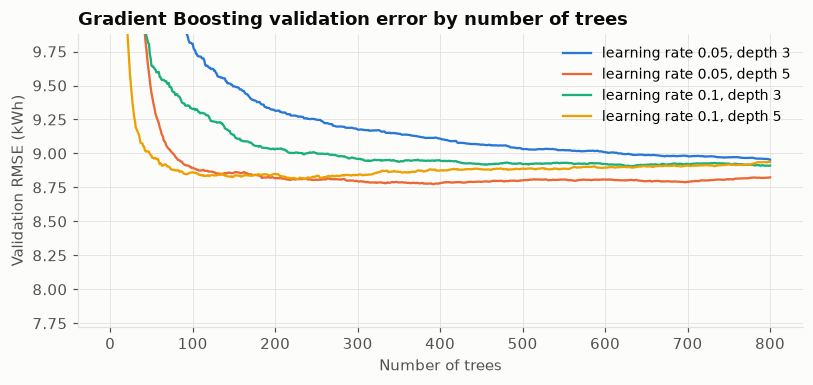

In [5]:
MAX_TREES = 800
gb_log, curves = [], {}
for params in ParameterGrid({'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}):
    t0 = time.time()
    gb = GradientBoostingRegressor(n_estimators=MAX_TREES, subsample=0.8, random_state=42, **params).fit(X_tr, y_tr)
    rmse_curve = np.array([np.sqrt(mean_squared_error(y_va, p)) for p in gb.staged_predict(X_va)])
    best_n = int(rmse_curve.argmin()) + 1
    curves[(params['learning_rate'], params['max_depth'])] = rmse_curve
    gb_log.append({**params, 'n_estimators': best_n, 'RMSE': rmse_curve[best_n - 1],
                   'RMSE_at_max_trees': rmse_curve[-1], 'fit_seconds': round(time.time() - t0, 1)})
gb_log = pd.DataFrame(gb_log).sort_values('RMSE')
gb_log.to_csv(OUT / 'tuning_gradient_boosting.csv', index=False)
print(gb_log.round(3).to_string(index=False))

best = gb_log.iloc[0]
gb_params = {'n_estimators': int(best.n_estimators), 'learning_rate': float(best.learning_rate),
             'max_depth': int(best.max_depth), 'subsample': 0.8}
gb = GradientBoostingRegressor(random_state=42, **gb_params).fit(X_tr, y_tr)
results['Gradient Boosting'] = {'params': gb_params, 'model': gb}
print('Selected:', gb_params)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for color, (key, curve) in zip(SERIES, curves.items()):
    ax.plot(np.arange(1, MAX_TREES + 1), curve, color=color, lw=1.5, label=f'learning rate {key[0]}, depth {key[1]}')
ax.set_ylim(top=min(c[20] for c in curves.values()))
ax.set_xlabel('Number of trees')
ax.set_ylabel('Validation RMSE (kWh)')
ax.set_title('Gradient Boosting validation error by number of trees')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG / 'md_gb_validation_curves.png', dpi=150)
plt.show()

## 6 Compare the models and benchmarks on validation
All models and naive benchmarks are scored on the exact same 5,088 validation intervals (`2018-09-16 00:15` to `2018-11-08 00:00`). Beyond overall MAE, RMSE, and $R^2$, we also inspect the **generalisation gap** (`val_RMSE - train_RMSE`), the **95th-percentile absolute error (`P95_AE`)**, and the **RMSE during `Maximum_Load` intervals (`MaxLoad_RMSE`)** to justify final model selection.

=== Validation Summary (Standard Metrics) ===
            model             kind    MAE   RMSE    R2  train_RMSE RMSE_vs_persistence
Gradient Boosting machine learning  4.131  8.775 0.919       7.620              +30.9%
    Random Forest machine learning  4.028  8.843 0.917       7.420              +30.4%
Linear Regression machine learning  6.571 11.191 0.868      12.794              +11.9%
      Persistence        benchmark  5.756 12.701 0.830         NaN               +0.0%
  Weekly seasonal        benchmark 13.032 25.065 0.337         NaN              -97.3%
   Daily seasonal        benchmark 15.283 28.906 0.118         NaN             -127.6%

=== Extended Diagnostic Metrics (Overfitting Gap & Peak/Tail Errors) ===
            model    MAE   RMSE    R2  train_RMSE  gen_gap_RMSE  P95_AE  MaxLoad_RMSE
Gradient Boosting  4.131  8.775 0.919       7.620         1.155  19.707        13.350
    Random Forest  4.028  8.843 0.917       7.420         1.424  19.647        13.264
Linear Regres

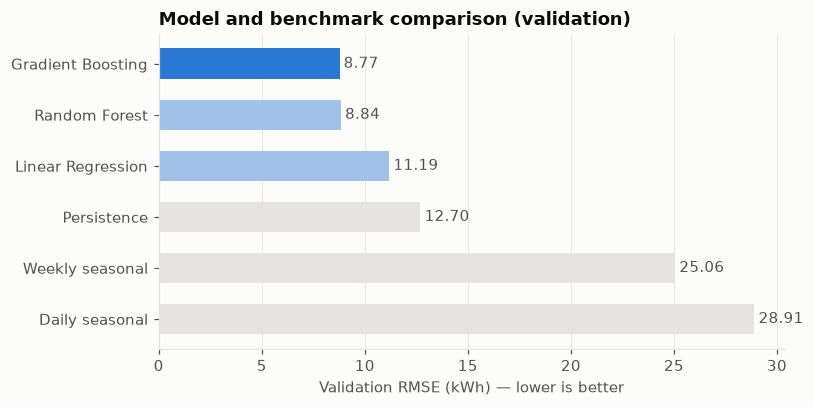

In [6]:
rows, detail_rows = [], []
val_preds = pd.DataFrame({'date': val.date.to_numpy(), 'actual': y_va.to_numpy(),
                          'load_type': val.analysis_load_type.to_numpy()})
max_mask = (val.analysis_load_type == 'Maximum_Load').to_numpy()

for name, col in BENCHMARKS.items():
    pred = val[col].to_numpy()
    m = metrics(y_va, pred)
    rows.append({'model': name, 'kind': 'benchmark', **m})
    detail_rows.append({
        'model': name, 'kind': 'benchmark', **m,
        'train_RMSE': np.nan, 'gen_gap_RMSE': np.nan,
        'P95_AE': float(np.percentile(np.abs(y_va - pred), 95)),
        'MaxLoad_RMSE': float(np.sqrt(mean_squared_error(y_va[max_mask], pred[max_mask])))
    })

for name, r in results.items():
    pred = r['model'].predict(X_va)
    val_preds[name] = pred
    m = metrics(y_va, pred)
    tr_rmse = metrics(y_tr, r['model'].predict(X_tr))['RMSE']
    rows.append({'model': name, 'kind': 'machine learning', **m, 'train_RMSE': tr_rmse})
    detail_rows.append({
        'model': name, 'kind': 'machine learning', **m,
        'train_RMSE': tr_rmse, 'gen_gap_RMSE': m['RMSE'] - tr_rmse,
        'P95_AE': float(np.percentile(np.abs(y_va - pred), 95)),
        'MaxLoad_RMSE': float(np.sqrt(mean_squared_error(y_va[max_mask], pred[max_mask])))
    })

comparison = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
persistence_rmse = comparison.set_index('model').loc['Persistence', 'RMSE']
comparison['RMSE_vs_persistence'] = (1 - comparison.RMSE / persistence_rmse).map('{:+.1%}'.format)
comparison.to_csv(OUT / 'validation_comparison.csv', index=False)
val_preds.to_csv(OUT / 'validation_predictions.csv', index=False)
print('=== Validation Summary (Standard Metrics) ===')
print(comparison.round(3).to_string(index=False))

detail_df = pd.DataFrame(detail_rows).sort_values('RMSE').reset_index(drop=True)
detail_df['RMSE_vs_persistence'] = (1 - detail_df.RMSE / persistence_rmse).map('{:+.1%}'.format)
detail_df.to_csv(OUT / 'validation_detailed_metrics.csv', index=False)
print('\n=== Extended Diagnostic Metrics (Overfitting Gap & Peak/Tail Errors) ===')
print(detail_df[['model', 'MAE', 'RMSE', 'R2', 'train_RMSE', 'gen_gap_RMSE', 'P95_AE', 'MaxLoad_RMSE']].round(3).to_string(index=False))

ml = comparison[comparison.kind == 'machine learning']
SELECTED_MODEL = ml.iloc[0].model
print('\nSelected final model (lowest validation RMSE):', SELECTED_MODEL)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
plot = comparison.iloc[::-1]
colors = [SERIES[0] if m == SELECTED_MODEL else ('#9fc1ea' if k == 'machine learning' else GRID)
          for m, k in zip(plot.model, plot.kind)]
ax.barh(plot.model, plot.RMSE, color=colors, height=0.6)
for y, v in enumerate(plot.RMSE):
    ax.text(v + 0.2, y, f'{v:.2f}', va='center', color=INK_2)
ax.set_xlabel('Validation RMSE (kWh) — lower is better')
ax.set_title('Model and benchmark comparison (validation)')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(FIG / 'md_validation_comparison.png', dpi=150)
plt.show()

## 6b Temporal stability check: 5-fold expanding-window cross-validation
Because single-window validation (`Sept–Nov 2018`) evaluates models on only one autumn operating regime, we also verify out-of-sample stability across the training timeline (`Jan–Sept 2018`) using a 5-fold chronological `TimeSeriesSplit`. Each fold trains strictly on earlier months and evaluates on the subsequent unseen block.

=== 5-Fold Expanding-Window TimeSeriesSplit Summary (Train Period) ===
                     MAE           RMSE            R2       
                    mean    std    mean    std   mean    std
model                                                       
Gradient Boosting  5.122  0.943  10.284  1.610  0.899  0.021
Linear Regression  7.518  0.880  12.353  1.239  0.855  0.014
Persistence        6.360  0.707  13.922  1.294  0.815  0.015
Random Forest      5.056  0.981  10.426  1.599  0.896  0.021


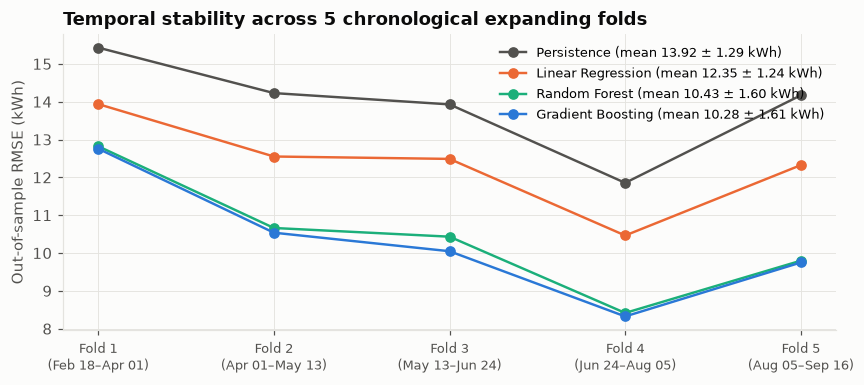

In [7]:
tscv = TimeSeriesSplit(n_splits=5)
cv_records = []
for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_tr), start=1):
    X_f_tr, y_f_tr = X_tr.iloc[tr_idx], y_tr.iloc[tr_idx]
    X_f_va, y_f_va = X_tr.iloc[va_idx], y_tr.iloc[va_idx]
    fold_dates = f"{train.date.iloc[va_idx[0]]:%b %d}–{train.date.iloc[va_idx[-1]]:%b %d}"

    # Persistence benchmark on fold
    pers_pred = train['bench_persistence'].iloc[va_idx]
    cv_records.append({'fold': fold, 'period': fold_dates, 'model': 'Persistence',
                       **metrics(y_f_va, pers_pred)})

    # Linear Regression on fold
    m_lin = make_linear().fit(X_f_tr, y_f_tr)
    cv_records.append({'fold': fold, 'period': fold_dates, 'model': 'Linear Regression',
                       **metrics(y_f_va, m_lin.predict(X_f_va))})

    # Random Forest (selected hyperparameters)
    m_rf = RandomForestRegressor(n_jobs=-1, random_state=42, **rf_params).fit(X_f_tr, y_f_tr)
    cv_records.append({'fold': fold, 'period': fold_dates, 'model': 'Random Forest',
                       **metrics(y_f_va, m_rf.predict(X_f_va))})

    # Gradient Boosting (selected hyperparameters)
    m_gb = GradientBoostingRegressor(random_state=42, **gb_params).fit(X_f_tr, y_f_tr)
    cv_records.append({'fold': fold, 'period': fold_dates, 'model': 'Gradient Boosting',
                       **metrics(y_f_va, m_gb.predict(X_f_va))})

cv_df = pd.DataFrame(cv_records)
cv_summary = (cv_df.groupby('model')[['MAE', 'RMSE', 'R2']]
              .agg(['mean', 'std'])
              .round(3))
cv_df.to_csv(OUT / 'timeseries_cv_folds.csv', index=False)
cv_summary.to_csv(OUT / 'timeseries_cv_summary.csv')
print('=== 5-Fold Expanding-Window TimeSeriesSplit Summary (Train Period) ===')
print(cv_summary.to_string())

fig, ax = plt.subplots(figsize=(8.0, 3.6))
for color, model_name in zip([INK_2, SERIES[1], SERIES[2], SERIES[0]],
                             ['Persistence', 'Linear Regression', 'Random Forest', 'Gradient Boosting']):
    sub = cv_df[cv_df.model == model_name]
    ax.plot(sub.fold, sub.RMSE, marker='o', color=color, lw=1.6,
            label=f"{model_name} (mean {sub.RMSE.mean():.2f} ± {sub.RMSE.std():.2f} kWh)")
ax.set_xticks(range(1, 6))
ax.set_xticklabels([f"Fold {r.fold}\n({r.period})" for _, r in cv_df[cv_df.model == 'Persistence'].iterrows()], fontsize=8.5)
ax.set_ylabel('Out-of-sample RMSE (kWh)')
ax.set_title('Temporal stability across 5 chronological expanding folds')
ax.legend(fontsize=8.5, loc='upper right')
fig.tight_layout()
fig.savefig(FIG / 'md_timeseries_cv.png', dpi=150)
plt.show()

## 7 Actual versus predicted for one validation week
The first full Monday-to-Sunday week of the validation period shows how each model tracks shift start-ups, daytime peaks, and the quieter weekend.

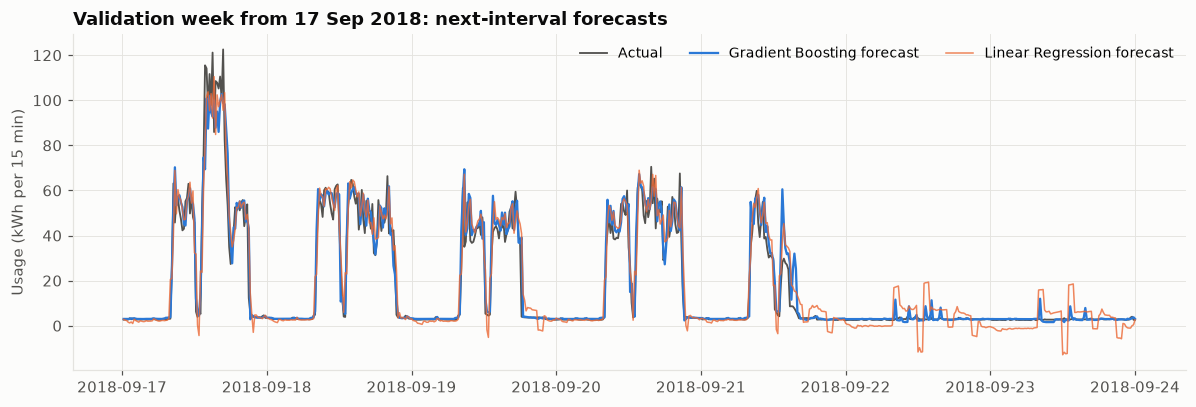

In [8]:
start = val_preds.date[val_preds.date.dt.dayofweek.eq(0) & val_preds.date.dt.hour.eq(0)
                       & val_preds.date.dt.minute.eq(15)].iloc[0]
week = val_preds[(val_preds.date >= start) & (val_preds.date < start + pd.Timedelta(days=7))]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(week.date, week.actual, color=INK_2, lw=1.2, label='Actual')
ax.plot(week.date, week[SELECTED_MODEL], color=SERIES[0], lw=1.5, label=f'{SELECTED_MODEL} forecast')
ax.plot(week.date, week['Linear Regression'], color=SERIES[1], lw=1.0, alpha=0.8, label='Linear Regression forecast')
ax.set_ylabel('Usage (kWh per 15 min)')
ax.set_title(f'Validation week from {start:%d %b %Y}: next-interval forecasts')
ax.legend(ncols=3, loc='upper right', fontsize=9)
fig.tight_layout()
fig.savefig(FIG / 'md_validation_week.png', dpi=150)
plt.show()

## 8 Where does the selected model make its errors?
The residuals (`actual − forecast`) are grouped by the load level recorded for the target interval and by hour of day. `Load_Type` is used here strictly for post-hoc diagnostics, never as a predictor. This identifies which plant operating regimes are hardest to anticipate.

=== Validation Error by Load_Type (Saved to validation_error_by_load_type.csv) ===
              intervals    MAE  mean_error
load_type                                 
Light_Load         2736  1.256      -0.299
Medium_Load        1344  6.199      -0.504
Maximum_Load       1008  9.177       0.007

=== Extended Load_Type Diagnostics (with RMSE and P95 Tail Error) ===
              intervals    MAE    RMSE  P95_AE  mean_bias
load_type                                                
Light_Load         2736  1.256   4.315   5.798     -0.299
Medium_Load        1344  6.199  10.951  24.296     -0.504
Maximum_Load       1008  9.177  13.350  28.346      0.007


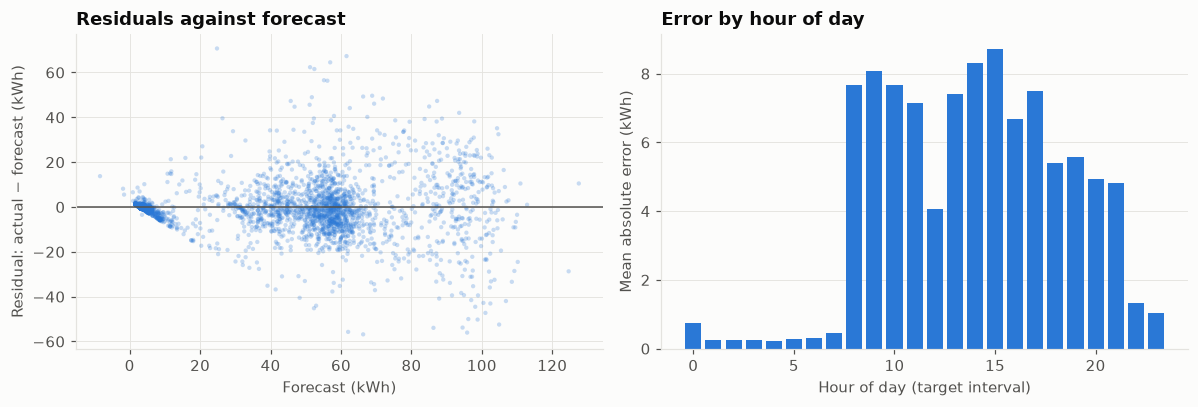

In [9]:
resid = val_preds.actual - val_preds[SELECTED_MODEL]
by_load = (pd.DataFrame({'load_type': val_preds.load_type, 'abs_error': resid.abs(), 'error': resid})
           .groupby('load_type').agg(intervals=('error', 'size'), MAE=('abs_error', 'mean'),
                                     mean_error=('error', 'mean'))
           .reindex(['Light_Load', 'Medium_Load', 'Maximum_Load']))
by_load.to_csv(OUT / 'validation_error_by_load_type.csv')
print('=== Validation Error by Load_Type (Saved to validation_error_by_load_type.csv) ===')
print(by_load.round(3).to_string())

# Extended breakdown including RMSE and 95th percentile absolute error per Load_Type
by_load_ext = (pd.DataFrame({'load_type': val_preds.load_type, 'abs_error': resid.abs(),
                             'sq_error': resid ** 2, 'error': resid})
               .groupby('load_type')
               .agg(intervals=('error', 'size'),
                    MAE=('abs_error', 'mean'),
                    RMSE=('sq_error', lambda s: float(np.sqrt(s.mean()))),
                    P95_AE=('abs_error', lambda s: float(np.percentile(s, 95))),
                    mean_bias=('error', 'mean'))
               .reindex(['Light_Load', 'Medium_Load', 'Maximum_Load']))
print('\n=== Extended Load_Type Diagnostics (with RMSE and P95 Tail Error) ===')
print(by_load_ext.round(3).to_string())

hourly = resid.abs().groupby(val_preds.date.dt.hour).mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(val_preds[SELECTED_MODEL], resid, s=8, alpha=0.25, color=SERIES[0], edgecolors='none')
axes[0].axhline(0, color=INK_2, lw=1)
axes[0].set_xlabel('Forecast (kWh)')
axes[0].set_ylabel('Residual: actual − forecast (kWh)')
axes[0].set_title('Residuals against forecast')
axes[1].bar(hourly.index, hourly.values, color=SERIES[0], width=0.8)
axes[1].set_xlabel('Hour of day (target interval)')
axes[1].set_ylabel('Mean absolute error (kWh)')
axes[1].set_title('Error by hour of day')
axes[1].grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig(FIG / 'md_residuals.png', dpi=150)
plt.show()

## 9 Which inputs does the selected model rely on?
Permutation importance shuffles one feature at a time (5 repeats) on the validation period and measures how much validation RMSE rises. Unlike impurity-based tree importance, it measures predictive contribution on unseen data. Note that importance reflects predictive association rather than causal impact: correlated features (such as recent usage and lagging reactive power) share credit.

                  feature  rmse_increase   std
              usage_lag_1         29.127 0.116
                  tod_cos          3.337 0.111
                  tod_sin          2.725 0.142
              usage_lag_2          1.349 0.047
             usage_diff_1          1.322 0.047
lead_reactive_kvarh_lag_1          1.090 0.116
 lag_reactive_kvarh_lag_1          0.455 0.016
              usage_lag_3          0.239 0.021
              usage_lag_4          0.225 0.031
   lag_power_factor_lag_1          0.215 0.031
                     hour          0.173 0.016
  lead_power_factor_lag_1          0.037 0.017
              day_of_week          0.033 0.020
               is_weekend          0.017 0.013


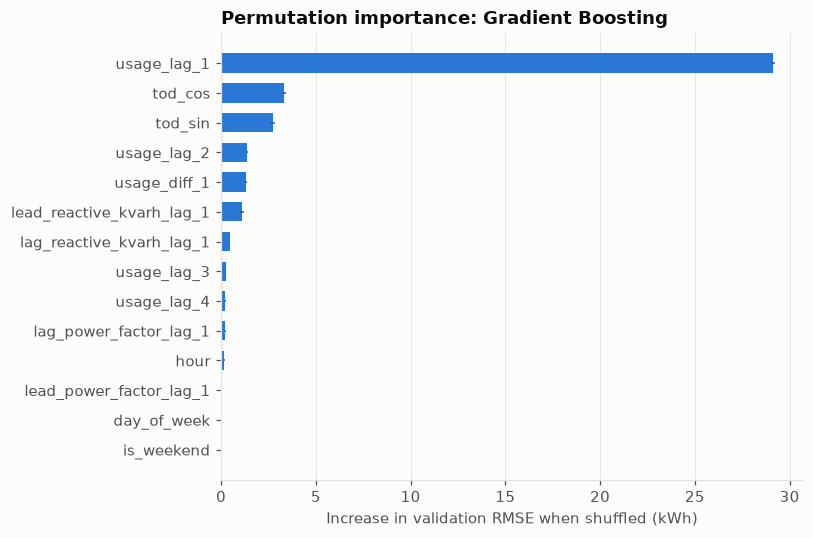

In [10]:
pi = permutation_importance(results[SELECTED_MODEL]['model'], X_va, y_va, n_repeats=5, random_state=0,
                            scoring='neg_root_mean_squared_error', n_jobs=-1)
importance = (pd.DataFrame({'feature': FEATURES, 'rmse_increase': pi.importances_mean, 'std': pi.importances_std})
              .sort_values('rmse_increase', ascending=False))
importance.to_csv(OUT / 'permutation_importance_validation.csv', index=False)
print(importance.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
plot = importance.iloc[::-1]
ax.barh(plot.feature, plot.rmse_increase, xerr=plot['std'], color=SERIES[0], height=0.65,
        error_kw={'ecolor': INK_2, 'lw': 1})
ax.set_xlabel('Increase in validation RMSE when shuffled (kWh)')
ax.set_title(f'Permutation importance: {SELECTED_MODEL}')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(FIG / 'md_permutation_importance.png', dpi=150)
plt.show()

## 10 Freeze the configurations and refit for testing
The hyperparameters selected on the validation set are now frozen. Each model is refitted on **train + validation** (`29,184` rows), representing the complete history available prior to the test split, and exported to `outputs/models/`.

### Handover Protocol for Feng (Final Evaluation)
1. Load `outputs/models/frozen_config.json` and the `.joblib` models.
2. Predict on `data.loc[data.split == 'test', FEATURES]` (5,184 rows).
3. Report MAE, RMSE, and $R^2$ alongside `bench_persistence`, `bench_daily_seasonal`, and `bench_weekly_seasonal` on the identical test timestamps.
4. **Do not retune any hyperparameters or alter the feature set.**

In [11]:
X_dev, y_dev = dev[FEATURES], dev[TARGET]
final_models = {'Linear Regression': make_linear(),
                'Random Forest': RandomForestRegressor(n_jobs=-1, random_state=42, **rf_params),
                'Gradient Boosting': GradientBoostingRegressor(random_state=42, **gb_params)}
files = {}
for name, model in final_models.items():
    model.fit(X_dev, y_dev)
    path = OUT / (name.lower().replace(' ', '_') + '.joblib')
    joblib.dump(model, path, compress=3)
    files[name] = str(path.relative_to(ROOT)).replace('\\', '/')
    print(f'{name:18s} -> {files[name]}  ({path.stat().st_size / 1e6:.1f} MB)')

frozen = {
    'selected_final_model': SELECTED_MODEL,
    'selection_metric': 'validation RMSE',
    'features': FEATURES,
    'target': TARGET,
    'trained_on': f'train + validation targets {dev.date.min()} to {dev.date.max()} ({len(dev):,} rows)',
    'hyperparameters': {'Linear Regression': 'OneHot(hour, day_of_week) + StandardScaler(numeric) + OLS',
                        'Random Forest': rf_params, 'Gradient Boosting': gb_params, 'random_state': 42},
    'validation_metrics': comparison.set_index('model')[['MAE', 'RMSE', 'R2']].round(4).to_dict('index'),
    'model_files': files,
    'test_protocol': "Load each model with joblib, predict data.loc[data.split == 'test', features], "
                     'compare with bench_* columns on the same rows. Do not retune.',
    'environment': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                    'pandas': pd.__version__, 'numpy': np.__version__},
}
(OUT / 'frozen_config.json').write_text(json.dumps(frozen, indent=2, default=str), encoding='utf-8')
print(json.dumps({k: frozen[k] for k in ['selected_final_model', 'hyperparameters']}, indent=2))

Linear Regression  -> outputs/models/linear_regression.joblib  (0.0 MB)


Random Forest      -> outputs/models/random_forest.joblib  (16.3 MB)


Gradient Boosting  -> outputs/models/gradient_boosting.joblib  (0.6 MB)
{
  "selected_final_model": "Gradient Boosting",
  "hyperparameters": {
    "Linear Regression": "OneHot(hour, day_of_week) + StandardScaler(numeric) + OLS",
    "Random Forest": {
      "n_estimators": 200,
      "max_depth": 16,
      "min_samples_leaf": 5,
      "max_features": 0.5
    },
    "Gradient Boosting": {
      "n_estimators": 391,
      "learning_rate": 0.05,
      "max_depth": 5,
      "subsample": 0.8
    },
    "random_state": 42
  }
}


## Completion checklist
- **Linear Regression** (plus **RidgeCV** collinearity diagnostic), **Random Forest**, and **Gradient Boosting** trained on the agreed 14 features.
- Hyperparameters tuned exclusively on the validation period; the test period was dropped immediately on load.
- All models compared against the persistence, daily-seasonal, and weekly-seasonal benchmarks across MAE, RMSE, $R^2$, generalisation gap, 95th-percentile tail error, and Maximum-Load RMSE.
- Temporal stability verified across 5 chronological expanding folds (`TimeSeriesSplit`) on the training period.
- Residual analysis by load level (`Load_Type`) and hour of day, plus validation permutation importance, exported for downstream interpretation.
- Frozen configurations and `train + validation` refits saved in `outputs/models/` for Feng's final test evaluation.